# 04 - LightGBM kidney-stone risk model (`nhanes_v003b`)

LightGBM uses the GPU learner only if the installed build supports it (the standard wheel does not), so the notebook checks and falls back to **CPU**. The previous run stopped after only 3-7 boosting rounds; **section 3b diagnoses that inside this notebook** (per-round curves, the metric that triggered the stop, six candidate causes) and the model is then fit with the fix: stop on AUC only (`first_metric_only=True`, patience 200), slow learning rate, shallow trees, large leaves, and exactly one imbalance strategy (chosen in section 4) instead of stacking weights and resampling.

**Ground rules.** Same frozen cycle-based split as `nhanes_v003` (train 2007-2014, validation 2015-2016, test 2017-2018), same features, same banned columns. The test cycle keeps its real ~10% prevalence, is never resampled and is never used to choose a threshold, hyper-parameters, a balancing method or features; it is first touched in section 10. Resampling (where used) happens only on **training** rows, inside the fit step of an `imblearn` Pipeline. The validation cycle is never resampled; it is split by `SEQN` (stratified) into an **early-stopping half** and a **calibration / threshold half** so the rows that decide where boosting stops are not the rows that calibrate probabilities and place thresholds.

**Two operating points**, both chosen on the validation calibration half only: `balanced` = maximum balanced accuracy; `accuracy` = maximum sensitivity subject to validation accuracy >= 72% (a margin above the 70% goal). About 90% of participants have no stone, so 'no stone for everyone' already scores ~90% accuracy; reaching > 70% accuracy is cheap and is bought with sensitivity. ROC-AUC and balanced accuracy are not expected to exceed 70%.

Every metric table in this notebook comes from one helper, `nhanes_common.show_metrics_table`.

Sections: 1 setup / device - 2 frozen splits and validation halves - 3 model + baseline fit - 4 class-imbalance comparison - 5 tuning - 6 calibration - 7 operating points - 8 leave-one-cycle-out CV - 9 freeze - 10 FINAL test evaluation - 11 imbalance strategies on test (display only) - 12 explanations - 13 save artifacts.

## 1. Setup and device check

In [1]:
import sys, json, time, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "ml" / "training" / "nhanes_common.py").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")
from IPython.display import Image, display

from ml.training import nhanes_common as nc

nc.set_seeds()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
print("repo root:", ROOT.name)
print("dry run (test cycle untouched, outputs in ml/outputs/_dryrun):", nc.is_dry_run())

NOTEBOOK_FILE = "04_lightgbm.ipynb"
MODEL_KEY = "lightgbm"
MODEL_NAME = f"{MODEL_KEY}_{nc.RUN_TAG}"
timer = nc.Timer()
devices = nc.probe_devices()
print(json.dumps(devices, indent=1))
print("libraries:", json.dumps(nc.library_versions()))
print("registered model name:", MODEL_NAME)

repo root: StoneSense-AI
dry run (test cycle untouched, outputs in ml/outputs/_dryrun): False


{
 "nvidia_smi": "NVIDIA GeForce RTX 5070 Laptop GPU, 8151 MiB, 592.15",
 "xgboost_cuda": true,
 "catboost_gpu": true,
 "lightgbm_gpu": false
}


libraries: {"python": "3.12.9", "numpy": "2.5.3", "pandas": "3.0.5", "sklearn": "1.9.0", "imblearn": "0.14.2", "xgboost": "3.4.1", "catboost": "1.2.10", "lightgbm": "4.7.0", "interpret": "0.7.8", "shap": "0.52.0", "joblib": "1.6.0"}
registered model name: lightgbm_nhanes_v003b


## 2. Load the frozen splits and cut the validation cycle in two

Only train and validation rows are loaded here. The preprocessor (median imputer, scaler, one-hot) is fit on the **training cycles only**. The validation cycle is split by `SEQN` into an **early-stopping half** (stopping point and tuning score) and a **calibration / threshold half** (strategy selection, calibration, both operating thresholds and every validation table). Neither half is resampled.

In [2]:
cfg = nc.load_feature_config()
splits = nc.load_frozen_splits(include_test=False)
manifest = nc.load_json(nc.artifacts_dir() / "split_manifest.json")
PRIMARY = cfg["primary_variant"]
dev_df = pd.concat([splits["train"], splits["validation"]], ignore_index=True)
print("split hash:", manifest["hash"][:16], "| train", len(splits["train"]), "| validation", len(splits["validation"]),
      "| positive rate train/val:", round(100 * splits["train"].target_stone.mean(), 2), "/", round(100 * splits["validation"].target_stone.mean(), 2), "%")
print("registered variant:", PRIMARY)
data = {v: nc.prepare_variant(splits, v, feats) for v, feats in cfg["variants"].items()}
print({v: len(vd.features) for v, vd in data.items()}, "features per variant")
assert not any(set(vd.features) & set(("KIQ026", "KIQ029", "SEQN", "CYCLE", "target_stone")) for vd in data.values())

# the validation cycle is cut (by SEQN, stratified) into an early-stopping half and a calibration / threshold half
halves = nc.split_validation(splits["validation"]["SEQN"].values, data[PRIMARY].y_val)
ES, CAL = halves["es"], halves["cal"]
VAL = {v: dict(Xes=vd.X_val[ES], yes=vd.y_val[ES], Xcal=vd.X_val[CAL], ycal=vd.y_val[CAL]) for v, vd in data.items()}
CAT = {v: nc.categorical_column_indices(vd.feature_names) for v, vd in data.items()}
print(f"validation early-stopping half: n={len(ES)} positives={int(VAL[PRIMARY]['yes'].sum())} ({100 * VAL[PRIMARY]['yes'].mean():.2f}%) | "
      f"calibration/threshold half: n={len(CAL)} positives={int(VAL[PRIMARY]['ycal'].sum())} ({100 * VAL[PRIMARY]['ycal'].mean():.2f}%) | halves hash {halves['hash'][:12]}")
print("categorical columns kept valid by SMOTENC (registered variant):", [data[PRIMARY].feature_names[i] for i in CAT[PRIMARY]])

split hash: a2c3bdb15ffb9f3b | train 23416 | validation 5705 | positive rate train/val: 8.86 / 10.62 %
registered variant: base_history_sensitive


{'base': 17, 'base_history': 21, 'base_history_sensitive': 23} features per variant
validation early-stopping half: n=2852 positives=303 (10.62%) | calibration/threshold half: n=2853 positives=303 (10.62%) | halves hash 06045bb720e5
categorical columns kept valid by SMOTENC (registered variant): ['RIAGENDR', 'BPQ020', 'BPQ080', 'DIQ010', 'MCQ080', 'RIDRETH1_1.0', 'RIDRETH1_2.0', 'RIDRETH1_3.0', 'RIDRETH1_4.0', 'RIDRETH1_5.0']


## 3. Model definition and early-stop diagnosis

Default hyper-parameters are fixed up front; early stopping (where it exists) watches **ROC-AUC on the early-stopping half only**.

In [3]:
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

DEVICE = "gpu" if devices["lightgbm_gpu"] else "cpu"
print("LightGBM GPU build available:", devices["lightgbm_gpu"], "-> training on:", DEVICE)
N_TRIALS = 4 if nc.is_dry_run() else 40
REFIT_FIXED = True
STOP_ROUNDS = 200
ES_METRICS = ["auc", "average_precision", "binary_logloss"]   # logged every round; ONLY the first one (AUC) decides the stop
# conservative defaults for a weak-signal problem (see section 3b for the evidence): slow learning rate, shallow trees, large leaves
DEFAULT_PARAMS = dict(learning_rate=0.03, num_leaves=7, max_depth=4, min_child_samples=100, subsample=0.8, colsample_bytree=0.8,
                      reg_lambda=5.0, reg_alpha=0.0, min_split_gain=0.0)

def sample_params(rng):
    return dict(learning_rate=float(rng.choice([0.02, 0.03, 0.04, 0.05])), num_leaves=int(rng.choice([7, 9, 11, 15])),
                max_depth=int(rng.choice([3, 4, 5])), min_child_samples=int(rng.choice([50, 100, 150, 200])),
                subsample=float(rng.choice([0.7, 0.8, 0.9])), colsample_bytree=float(rng.choice([0.7, 0.8, 0.9])),
                reg_lambda=float(rng.choice([1, 3, 5, 10])), reg_alpha=float(rng.choice([0, 0.1, 1])),
                min_split_gain=float(rng.choice([0, 0.01, 0.05])))

def _lgb(params, n_estimators, strategy, ytr, **extra):
    spw = nc.class_weight_ratio(ytr) if strategy == "class_weight" else 1.0
    return lgb.LGBMClassifier(n_estimators=int(n_estimators), **params, subsample_freq=1, scale_pos_weight=spw, device=DEVICE,
                              random_state=nc.SEED, n_jobs=4, verbose=-1, **extra)

def fit_es(Xtr, ytr, Xes, yes, params, strategy, cat_idx, record_train=False):
    """Early stopping on the FIRST metric only (validation AUC, patience STOP_ROUNDS); every metric is still logged."""
    est = _lgb(params, 5000, strategy, ytr, first_metric_only=True)
    eval_set, names = [(Xes, yes)], ["es"]
    if record_train:
        eval_set, names = [(Xtr, ytr), (Xes, yes)], ["train", "es"]
    pipe = nc.fit_with_strategy(est, strategy, Xtr, ytr, cat_idx, fit_params=dict(
        eval_set=eval_set, eval_names=names, eval_metric=ES_METRICS,
        callbacks=[lgb.early_stopping(STOP_ROUNDS, first_metric_only=True, verbose=False)]))
    m = pipe.named_steps["clf"]
    return m, int(m.best_iteration_), len(m.evals_result_[names[-1]]["auc"])   # rounds actually trained (best + patience)

def fit_fixed(Xtr, ytr, params, n_trees, strategy, cat_idx):
    return nc.fit_with_strategy(_lgb(params, max(int(n_trees), 1), strategy, ytr), strategy, Xtr, ytr, cat_idx).named_steps["clf"]

def finalize_estimator(m):
    return m

def actual_device(m):
    return m.get_params()["device"]

LightGBM GPU build available: False -> training on: cpu


### 3b. Why did LightGBM stop after fewer than 10 rounds?

The old call was `eval_metric='auc'` with `early_stopping(150)` and `scale_pos_weight`. In LightGBM the default objective metric (`binary_logloss`) is evaluated **in addition** to the requested one, and the callback stops as soon as **any** metric has not improved for 150 rounds. With `scale_pos_weight` the model's probabilities are inflated, so the *unweighted* validation logloss is at its best after a handful of rounds and then rises. The cells below test that against the alternatives (a)-(f) instead of assuming it: the old setup is replicated, per-round curves are computed without early stopping, and each candidate cause gets a verdict.

In [4]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# --- the previous (nhanes_v003) run, for the before / after comparison
PREV = nc.load_json(nc.PROJECT_ROOT / "ml" / "outputs" / "metrics" / nc.MODEL_VERSION / "_prev_v003" / "lightgbm.json")
OLD_PARAMS = PREV["variants"][PRIMARY]["tuning"]["best_params"]
PREV_LGB_BEST_ITER = PREV["variants"][PRIMARY]["tuning"]["n_trees"]
print("nhanes_v003 LightGBM (registered variant): best_iteration_ =", PREV_LGB_BEST_ITER, "| per variant:",
      {v: PREV["variants"][v]["tuning"]["n_trees"] for v in PREV["variants"]})
print("old tuned params:", OLD_PARAMS)

vdp = data[PRIMARY]
Xtr, ytr = vdp.X_train, vdp.y_train
Xv_full, yv_full = vdp.X_val, vdp.y_val          # the whole 2015-2016 cycle, exactly what the old notebook early-stopped AND calibrated on
RATIO = nc.class_weight_ratio(ytr)
print(f"train positive rate {100 * ytr.mean():.2f}% | validation cycle positive rate {100 * yv_full.mean():.2f}% | scale_pos_weight used before = {RATIO:.2f}")

def _model(params, spw, rounds, **extra):
    return lgb.LGBMClassifier(n_estimators=rounds, **params, subsample_freq=1, scale_pos_weight=spw, device=DEVICE,
                              random_state=nc.SEED, n_jobs=4, verbose=-1, **extra)

def curves(params, spw, Xa, ya, Xb, yb, rounds=1200):
    """Per-round train and validation curves WITHOUT early stopping, for three metrics."""
    m = _model(params, spw, rounds)
    m.fit(Xa, ya, eval_set=[(Xa, ya), (Xb, yb)], eval_names=["train", "val"], eval_metric=ES_METRICS)
    return m.evals_result_

def best_it(res, metric, split="val"):
    c = np.asarray(res[split][metric])
    return int((c.argmin() if metric == "binary_logloss" else c.argmax()) + 1)

# (d) an in-distribution check: hold out 20% of the TRAINING cycles instead of using the 2015-2016 cycle
itr, iho = train_test_split(np.arange(len(ytr)), test_size=0.2, stratify=ytr, random_state=nc.SEED)
scen = {
    "S1 old tuned params + scale_pos_weight, val = 2015-2016 (the old setup)": curves(OLD_PARAMS, RATIO, Xtr, ytr, Xv_full, yv_full),
    "S2 old tuned params, NO class weight, val = 2015-2016": curves(OLD_PARAMS, 1.0, Xtr, ytr, Xv_full, yv_full),
    "S3 old tuned params + scale_pos_weight, val = random 20% of train cycles": curves(OLD_PARAMS, RATIO, Xtr[itr], ytr[itr], Xtr[iho], ytr[iho]),
    "S4 NEW default params, NO class weight, val = ES half of 2015-2016": curves(DEFAULT_PARAMS, 1.0, Xtr, ytr, VAL[PRIMARY]["Xes"], VAL[PRIMARY]["yes"]),
    "S5 NEW default params + scale_pos_weight, val = ES half of 2015-2016": curves(DEFAULT_PARAMS, RATIO, Xtr, ytr, VAL[PRIMARY]["Xes"], VAL[PRIMARY]["yes"]),
}
PAT_OLD = 150
rows = []
for name, r in scen.items():
    b = {m: best_it(r, m) for m in ES_METRICS}
    stop_any = min(b.values()) + PAT_OLD            # old callback: stops when ANY metric has not improved for 150 rounds
    trig = min(b, key=b.get)
    gap = r["train"]["auc"][b["auc"] - 1] - r["val"]["auc"][b["auc"] - 1]
    rows.append({"scenario": name, "best AUC": b["auc"], "best AP": b["average_precision"], "best logloss": b["binary_logloss"],
                 "old rule (any metric, patience 150) stops at": stop_any, "triggered by": trig, "first-metric-only (AUC) stops at": b["auc"] + PAT_OLD,
                 "train-val AUC gap @best AUC": round(float(gap), 3)})
diag_table = pd.DataFrame(rows).set_index("scenario")
print("=== per-metric best round on the validation curve (no early stopping; 1,200 rounds trained) ===")
print(diag_table.to_string())

# --- replicate the OLD callback exactly, to confirm what it did
m_old = _model(OLD_PARAMS, RATIO, 3000)
m_old.fit(Xtr, ytr, eval_set=[(Xv_full, yv_full)], eval_metric="auc", callbacks=[lgb.early_stopping(150, verbose=False)])
old_best, old_rounds = int(m_old.best_iteration_), len(m_old.evals_result_["valid_0"]["auc"])
print(f"\nOLD configuration replicated: best_iteration_ = {old_best}, rounds trained = {old_rounds} (nhanes_v003 reported {PREV_LGB_BEST_ITER})")
print("best_score_ at the stop:", {k: {m: round(float(x), 4) for m, x in v.items()} for k, v in m_old.best_score_.items()})
s1 = diag_table.iloc[0]
print(f"metric that triggered the old stop: {s1['triggered by']} (its best round {int(s1[['best AUC','best AP','best logloss']].min())}, + 150 patience = round {int(s1['old rule (any metric, patience 150) stops at'])})")

nhanes_v003 LightGBM (registered variant): best_iteration_ = 3 | per variant: {'base': 4, 'base_history': 7, 'base_history_sensitive': 3}
old tuned params: {'learning_rate': 0.03, 'num_leaves': 15, 'min_child_samples': 50, 'subsample': 0.9, 'colsample_bytree': 1.0, 'reg_lambda': 5.0, 'reg_alpha': 1.0, 'min_split_gain': 0.0}
train positive rate 8.86% | validation cycle positive rate 10.62% | scale_pos_weight used before = 10.29


=== per-metric best round on the validation curve (no early stopping; 1,200 rounds trained) ===
                                                                          best AUC  best AP  best logloss  old rule (any metric, patience 150) stops at    triggered by  first-metric-only (AUC) stops at  train-val AUC gap @best AUC
scenario                                                                                                                                                                                                                              
S1 old tuned params + scale_pos_weight, val = 2015-2016 (the old setup)        159      298             3                                           153  binary_logloss                               309                        0.120
S2 old tuned params, NO class weight, val = 2015-2016                          269      237           117                                           267  binary_logloss                               419          

=== old parameters + scale_pos_weight, metrics [auc, average_precision, binary_logloss] ===
 stopping_rounds  first_metric_only  best_iteration_  rounds trained
              30              False                3              33
              30               True              122             152
             150              False                3             153
             150               True              159             309
             200              False                3             203
             200               True              159             359


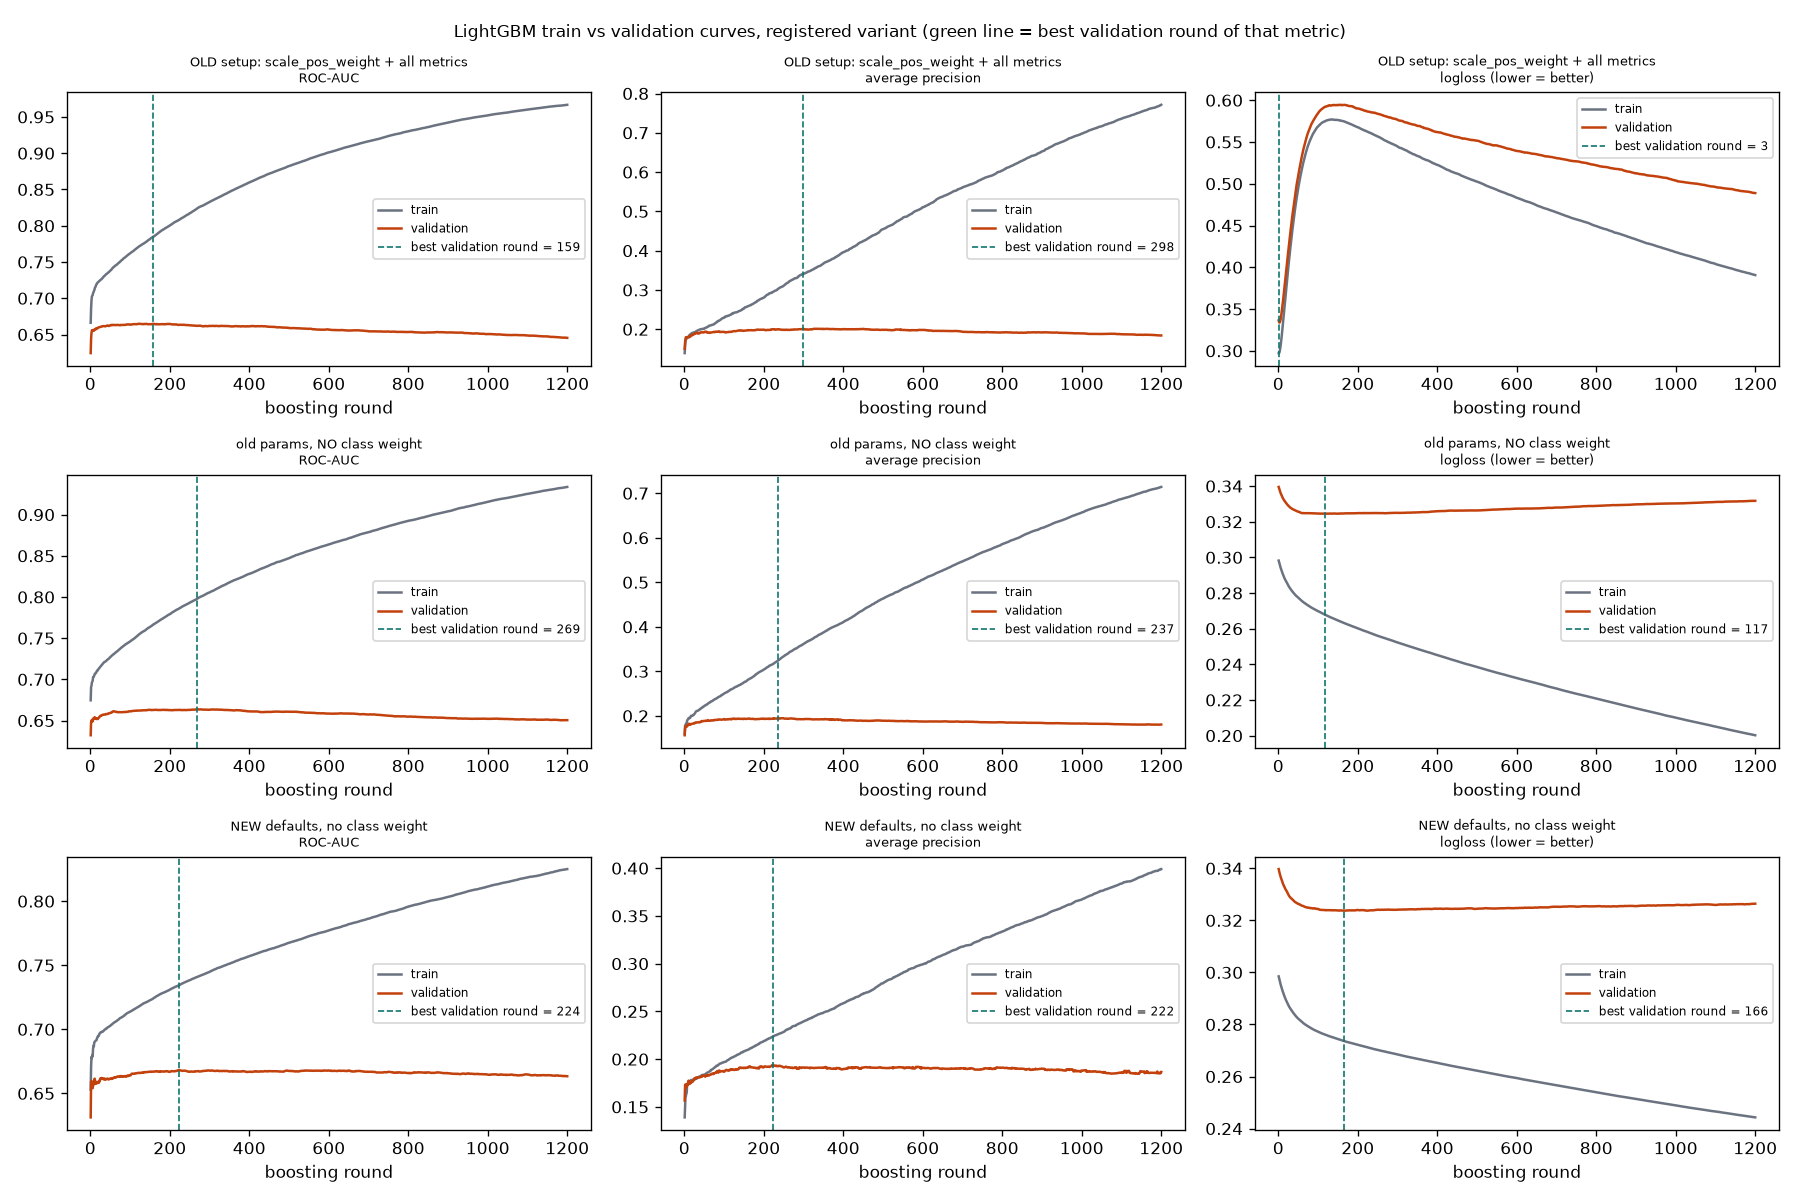


=== verdict on the suspected causes ===
TRUE : (a) early stopping used another metric (logloss) instead of AUC
TRUE : (b) scale_pos_weight inflates probabilities, so UNWEIGHTED validation logloss rises at once
false: (c) learning rate / leaves too loose (old params reach their logloss minimum much sooner than the new defaults, even unweighted)
false: (d) validation cycle differs from the training cycles (logloss minimum comes earlier there than on a random train hold-out)
false: (e) stopping_rounds too small (patience 200 would not stop at the same place as 150)
TRUE : (f) same validation rows used for early stopping AND calibration / thresholds
(f) was true of the old notebook by construction; here the 2015-2016 cycle is split by SEQN into an early-stopping half and a calibration/threshold half.



FIX: stop on AUC only (first_metric_only=True, patience 200), conservative params {'learning_rate': 0.03, 'num_leaves': 7, 'max_depth': 4, 'min_child_samples': 100, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 5.0, 'reg_alpha': 0.0, 'min_split_gain': 0.0}
BEFORE best_iteration_ = 3 (rounds trained 153) -> AFTER best_iteration_ = 224 (rounds trained 424) with the new defaults and no class weight


20.08

In [5]:
# (e) stopping_rounds: does a larger patience change anything under the old rule? And does first_metric_only fix it?
rows = []
for patience in (30, 150, 200):
    for fmo in (False, True):
        m = _model(OLD_PARAMS, RATIO, 3000, first_metric_only=fmo)
        m.fit(Xtr, ytr, eval_set=[(Xv_full, yv_full)], eval_metric=ES_METRICS, eval_names=["val"],
              callbacks=[lgb.early_stopping(patience, first_metric_only=fmo, verbose=False)])
        rows.append({"stopping_rounds": patience, "first_metric_only": fmo, "best_iteration_": int(m.best_iteration_),
                     "rounds trained": len(m.evals_result_["val"]["auc"])})
patience_table = pd.DataFrame(rows)
print("=== old parameters + scale_pos_weight, metrics [auc, average_precision, binary_logloss] ===")
print(patience_table.to_string(index=False))

# plots: train vs validation for the old and the fixed set-ups, with the best round of each metric marked
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
s_keys = list(scen)
plot_scen = [(s_keys[0], "OLD setup: scale_pos_weight + all metrics"), (s_keys[1], "old params, NO class weight"), (s_keys[3], "NEW defaults, no class weight")]
labels = {"binary_logloss": "logloss (lower = better)", "auc": "ROC-AUC", "average_precision": "average precision"}
for i, (key, title) in enumerate(plot_scen):
    r = scen[key]
    for j, met in enumerate(ES_METRICS):
        ax = axes[i, j]
        ax.plot(range(1, len(r["train"][met]) + 1), r["train"][met], label="train", color="#6b7280")
        ax.plot(range(1, len(r["val"][met]) + 1), r["val"][met], label="validation", color="#c2410c")
        b = best_it(r, met)
        ax.axvline(b, color="#0f766e", ls="--", lw=1, label=f"best validation round = {b}")
        ax.set_title(f"{title}\n{labels[met]}", fontsize=8)
        ax.set_xlabel("boosting round")
        ax.legend(fontsize=7)
fig.suptitle("LightGBM train vs validation curves, registered variant (green line = best validation round of that metric)", fontsize=10)
fig.tight_layout()
nc.ensure(nc.charts_dir())
fig.savefig(nc.charts_dir() / "lightgbm_early_stop_curves.png", dpi=120)
plt.close(fig)
display(Image(filename=str(nc.charts_dir() / "lightgbm_early_stop_curves.png")))

# verdict on each suspected cause (rules stated here; numbers are in the tables above)
B = {i + 1: {m: best_it(scen[k], m) for m in ES_METRICS} for i, k in enumerate(s_keys)}
pt = patience_table.query("first_metric_only == False").set_index("stopping_rounds")["best_iteration_"]
verdict = {
    "(a) early stopping used another metric (logloss) instead of AUC": bool(old_best < 30 and B[1]["auc"] > 3 * max(old_best, 1)),
    "(b) scale_pos_weight inflates probabilities, so UNWEIGHTED validation logloss rises at once": bool(B[1]["binary_logloss"] <= 30 and B[2]["binary_logloss"] > 2 * B[1]["binary_logloss"]),
    "(c) learning rate / leaves too loose (old params reach their logloss minimum much sooner than the new defaults, even unweighted)": bool(B[4]["binary_logloss"] > 1.5 * B[2]["binary_logloss"]),
    "(d) validation cycle differs from the training cycles (logloss minimum comes earlier there than on a random train hold-out)": bool(B[3]["binary_logloss"] > 3 * max(B[1]["binary_logloss"], 1)),
    "(e) stopping_rounds too small (patience 200 would not stop at the same place as 150)": bool(pt.loc[200] != pt.loc[150]),
    "(f) same validation rows used for early stopping AND calibration / thresholds": True,
}
print("\n=== verdict on the suspected causes ===")
for k_, v_ in verdict.items():
    print(("TRUE : " if v_ else "false: ") + k_)
print("(f) was true of the old notebook by construction; here the 2015-2016 cycle is split by SEQN into an early-stopping half and a calibration/threshold half.")
fixed_model, fixed_best, fixed_rounds = fit_es(Xtr, ytr, VAL[PRIMARY]["Xes"], VAL[PRIMARY]["yes"], DEFAULT_PARAMS, "none", CAT[PRIMARY])
print(f"\nFIX: stop on AUC only (first_metric_only=True, patience {STOP_ROUNDS}), conservative params {DEFAULT_PARAMS}")
print(f"BEFORE best_iteration_ = {old_best} (rounds trained {old_rounds}) -> AFTER best_iteration_ = {fixed_best} (rounds trained {fixed_rounds}) with the new defaults and no class weight")
DIAG = {"before_best_iteration": old_best, "before_rounds_trained": old_rounds, "nhanes_v003_reported_best_iteration": PREV_LGB_BEST_ITER,
        "trigger_metric": s1["triggered by"], "verdict": {k_: bool(v_) for k_, v_ in verdict.items()}, "after_default_best_iteration": fixed_best,
        "after_default_rounds_trained": fixed_rounds, "per_metric_best_rounds": diag_table.reset_index().to_dict(orient="records"),
        "patience_table": patience_table.to_dict(orient="records"), "stopping_rounds_new": STOP_ROUNDS, "first_metric_only_new": True,
        "curves_chart": "ml/outputs/charts/nhanes_v003/lightgbm_early_stop_curves.png"}
timer.lap("lightgbm_diagnosis")

### Baseline fit

Default hyper-parameters, **no balancing**, raw scores, every feature variant. Threshold-dependent columns use each score vector's own validation operating points (balanced / accuracy rules), because raw scores have no natural cut-off.

In [6]:
results = {"model": MODEL_KEY, "model_name": MODEL_NAME, "variants": {}}
base_entries, base_extra = {}, {}
for v, vd in data.items():
    clf, best_it, rounds = fit_es(vd.X_train, vd.y_train, VAL[v]["Xes"], VAL[v]["yes"], DEFAULT_PARAMS, "none", CAT[v])
    p = clf.predict_proba(VAL[v]["Xcal"])[:, 1]
    base_entries[v] = (VAL[v]["ycal"], p)
    base_extra[v] = {"best_iter": best_it, "rounds": rounds}
    results["variants"][v] = {"features": vd.features, "baseline_validation": {**nc.rank_metrics(VAL[v]["ycal"], p), "best_iteration": best_it, "rounds_trained": rounds}}
print("device actually used for training:", actual_device(clf))
baseline_table = nc.show_metrics_table(base_entries, "BASELINE fit - default params, no balancing, raw scores - validation (calibration half)",
                                       name=f"{MODEL_KEY}_01_baseline", extra=base_extra)
timer.lap("baseline")

device actually used for training: cpu
=== METRICS TABLE: BASELINE fit - default params, no balancing, raw scores - validation (calibration half) ===
        model/strategy    point Threshold ROC-AUC PR-AUC  Brier Accuracy Balanced acc Sensitivity Specificity Precision    F1   MCC Majority acc Pos-pred rate   TN   FP  FN  TP  best_iter  rounds
                  base balanced    0.0901   0.644  0.165 0.0941    0.623        0.610       0.594       0.626     0.159 0.251 0.138        0.894         0.397 1596  954 123 180         14     214
                  base accuracy    0.0963   0.644  0.165 0.0941    0.721        0.592       0.429       0.756     0.173 0.246 0.129        0.894         0.264 1927  623 173 130         14     214
          base_history balanced    0.0880   0.646  0.182 0.0924    0.606        0.615       0.627       0.603     0.158 0.252 0.144        0.894         0.421 1538 1012 113 190        534     734
          base_history accuracy    0.1147   0.646  0.182 0.0924   

2.14

## 4. Class-imbalance comparison (registered variant, default hyper-parameters)

On the same frozen split: (i) **none**, (ii) **class weights** (`scale_pos_weight` / `sample_weight` / `class_weight`), (iii) **random oversampling**, (iv) **random undersampling**, (v) **SMOTENC**. Plain SMOTE would invent in-between values for the binary columns (sex, the yes/no history flags, the one-hot race columns), so SMOTENC is told which columns are categorical (printed in section 2). All resampling runs inside an `imblearn` Pipeline, so it only ever sees training rows.

Balanced training inflates raw probabilities (average predicted risk goes from ~10% towards ~50%), so every strategy is **calibrated on the real-prevalence validation calibration half** (isotonic vs sigmoid by cross-validated Brier). The strategy is selected on validation only by a rule declared in advance: best post-calibration PR-AUC; strategies within 0.005 PR-AUC are treated as tied and the lowest Brier then the simplest wins. The expectation that balancing mostly shifts the decision threshold and rarely improves ROC-AUC is **tested**, not assumed.

In [7]:
vd, V = data[PRIMARY], VAL[PRIMARY]
n_pos, n_neg = int(vd.y_train.sum()), int((vd.y_train == 0).sum())
rows_seen = {"none": n_pos + n_neg, "class_weight": n_pos + n_neg, "random_over": 2 * n_neg, "random_under": 2 * n_pos, "smotenc": 2 * n_neg}
strat_fit, strat_rows = {}, []
for s in nc.IMBALANCE_STRATEGIES:
    t0 = time.perf_counter()
    clf, bi, rounds = fit_es(vd.X_train, vd.y_train, V["Xes"], V["yes"], DEFAULT_PARAMS, s, CAT[PRIMARY])
    p_raw = clf.predict_proba(V["Xcal"])[:, 1]
    sel = nc.calibrated_oof_metrics(p_raw, V["ycal"])
    cal, rep = nc.choose_calibrator(p_raw, V["ycal"])
    strat_fit[s] = dict(clf=clf, cal=cal, p_raw=p_raw, p_cal=cal.predict(p_raw), best_iteration=bi)
    strat_rows.append({"strategy": s, "train_rows_fitted": rows_seen[s], "best_iter": bi, "mean_raw_risk": sel["mean_raw_risk"], **{k: sel[k] for k in
                       ("calibration_method", "mean_calibrated_risk", "oof_roc_auc", "oof_pr_auc", "oof_brier")}, "fit_seconds": round(time.perf_counter() - t0, 1)})
strat_table = pd.DataFrame(strat_rows).set_index("strategy")
print("Strategy comparison, registered variant, default hyper-parameters. Resampling touched TRAINING rows only; validation/test keep their real prevalence")
print(f"(validation calibration half prevalence = {100 * V['ycal'].mean():.2f}%). 'oof_*' = cross-validated metrics of the CALIBRATED probabilities.")
print(strat_table.round(4).to_string())
SELECTED, select_info = nc.select_strategy(strat_table)
print(f"\nSELECTED strategy (validation only; rule: best post-calibration PR-AUC, strategies within {nc.STRATEGY_TIE_BAND} PR-AUC tie, then lowest Brier): "
      f"{SELECTED} ({nc.STRATEGY_LABEL[SELECTED]})")
print("tied with:", select_info["tied_with"], "| 'none' within the tie band:", select_info["none_within_tie_band"],
      "| PR-AUC gain of the selection over 'none':", round(select_info["pr_auc_gain_over_none"], 4))
print("ROC-AUC range across strategies after calibration:", round(strat_table.oof_roc_auc.min(), 4), "-", round(strat_table.oof_roc_auc.max(), 4))
strat_val_table = nc.show_metrics_table({s: (V["ycal"], strat_fit[s]["p_cal"]) for s in nc.IMBALANCE_STRATEGIES},
                                        "IMBALANCE STRATEGIES (each calibrated on the real-prevalence validation half; thresholds from validation) - validation",
                                        name=f"{MODEL_KEY}_02_imbalance_validation",
                                        extra={s: {"mean_raw_risk": round(strat_table.loc[s, "mean_raw_risk"], 3)} for s in nc.IMBALANCE_STRATEGIES})
timer.lap("imbalance_comparison")

Strategy comparison, registered variant, default hyper-parameters. Resampling touched TRAINING rows only; validation/test keep their real prevalence
(validation calibration half prevalence = 10.62%). 'oof_*' = cross-validated metrics of the CALIBRATED probabilities.
              train_rows_fitted  best_iter  mean_raw_risk calibration_method  mean_calibrated_risk  oof_roc_auc  oof_pr_auc  oof_brier  fit_seconds
strategy                                                                                                                                           
none                      23416        224         0.0875            sigmoid                0.1063       0.6580      0.1907     0.0917          0.7
class_weight              23416        432         0.4255            sigmoid                0.1063       0.6554      0.1892     0.0919          1.0
random_over               42684        567         0.4229            sigmoid                0.1063       0.6497      0.1917     0.0919       

6.6

## 5. Hyper-parameter tuning with the selected strategy

Random search scored by **validation ROC-AUC on the early-stopping half** (PR-AUC is logged alongside); the first trial is the default configuration. Never the test cycle. Exactly the one strategy selected in section 4 is used (no stacking of weights and resampling).

In [8]:
tuning, estimators, n_trees, p_val_raw, rounds_trained = {}, {}, {}, {}, {}
for v, vd in data.items():
    def fit_eval(params, vd=vd, v=v):
        clf, bi, _ = fit_es(vd.X_train, vd.y_train, VAL[v]["Xes"], VAL[v]["yes"], params, SELECTED, CAT[v])
        p = clf.predict_proba(VAL[v]["Xes"])[:, 1]
        return {"val_roc_auc": float(roc_auc_score(VAL[v]["yes"], p)), "val_pr_auc": float(average_precision_score(VAL[v]["yes"], p)),
                "n_trees": bi}
    best, trials = nc.random_search(sample_params, fit_eval, N_TRIALS, seed=nc.SEED, first_params=DEFAULT_PARAMS)
    clf, bi, rounds = fit_es(vd.X_train, vd.y_train, VAL[v]["Xes"], VAL[v]["yes"], best, SELECTED, CAT[v])
    est = fit_fixed(vd.X_train, vd.y_train, best, bi, SELECTED, CAT[v]) if REFIT_FIXED else clf
    estimators[v], n_trees[v], rounds_trained[v] = est, bi, rounds
    p_val_raw[v] = est.predict_proba(VAL[v]["Xcal"])[:, 1]
    tuning[v] = {"best_params": best, "n_trials": int(len(trials)), "imbalance_strategy": SELECTED,
                 "tuning_score": "ROC-AUC on the validation early-stopping half", "best_val_roc_auc_es_half": float(trials["val_roc_auc"].max()),
                 "best_iteration": bi, "rounds_trained": rounds, "n_trees": bi,
                 "final_val_roc_auc_cal_half": float(roc_auc_score(VAL[v]["ycal"], p_val_raw[v]))}
    results["variants"][v]["tuning"] = tuning[v]
    nc.ensure(nc.metrics_dir())
    trials.to_csv(nc.metrics_dir() / f"{MODEL_KEY}_tuning_{v}.csv", index=False)
display(pd.DataFrame({v: {k: tuning[v][k] for k in ("n_trials", "best_val_roc_auc_es_half", "final_val_roc_auc_cal_half", "best_iteration", "rounds_trained")} for v in data}).T)
print("best params (registered variant):", tuning[PRIMARY]["best_params"])
print("imbalance strategy used for tuning and the final fit:", SELECTED)
TRAIN_DEVICE = actual_device(estimators[PRIMARY])      # recorded now: finalize_estimator() may later switch XGBoost to CPU for serving
print("device actually used for the final fit:", TRAIN_DEVICE)
tuned_table = nc.show_metrics_table({v: (VAL[v]["ycal"], p_val_raw[v]) for v in data},
                                    "AFTER TUNING - raw (uncalibrated) scores - validation (calibration half)", name=f"{MODEL_KEY}_03_tuned",
                                    extra={v: {"best_iter": tuning[v]["best_iteration"], "rounds": tuning[v]["rounds_trained"]} for v in data})
timer.lap("tuning_and_final_fit")

,n_trials,best_val_roc_auc_es_half,final_val_roc_auc_cal_half,best_iteration,rounds_trained
base,40.0,0.632832,0.636714,818.0,1018.0
base_history,40.0,0.647407,0.645013,407.0,607.0
base_history_sensitive,40.0,0.672570,0.660092,190.0,390.0


best params (registered variant): {'learning_rate': 0.05, 'num_leaves': 7, 'max_depth': 5, 'min_child_samples': 200, 'subsample': 0.7, 'colsample_bytree': 0.7, 'reg_lambda': 3.0, 'reg_alpha': 1.0, 'min_split_gain': 0.05}
imbalance strategy used for tuning and the final fit: none
device actually used for the final fit: cpu
=== METRICS TABLE: AFTER TUNING - raw (uncalibrated) scores - validation (calibration half) ===
        model/strategy    point Threshold ROC-AUC PR-AUC  Brier Accuracy Balanced acc Sensitivity Specificity Precision    F1   MCC Majority acc Pos-pred rate   TN  FP  FN  TP  best_iter  rounds
                  base balanced    0.1232   0.637  0.172 0.0930    0.750        0.597       0.403       0.792     0.187 0.255 0.143        0.894         0.229 2019 531 181 122        818    1018
                  base accuracy    0.1139   0.637  0.172 0.0930    0.720        0.591       0.426       0.755     0.171 0.244 0.127        0.894         0.264 1926 624 174 129        818    

101.92

### Boosting-round check, all three boosted models (before anything is calibrated or scored on test)

In [9]:
# best_iteration_ / rounds trained of the three boosted models (XGBoost and CatBoost come from their executed notebooks 03 / 02)
def _read(key):
    path = nc.metrics_dir() / f"{key}.json"
    assert path.exists(), f"{key}.json missing - run notebooks 02 and 03 before 04"
    j = nc.load_json(path)
    assert j.get("provenance", {}).get("notebook"), f"{key}.json has no provenance - it is not from the nhanes_v003b run"
    return j
rows = []
for key, label in (("xgboost", "XGBoost"), ("catboost", "CatBoost")):
    j = _read(key)
    t = j["variants"][j["primary_variant"]]["tuning"]
    rows.append({"model": label, "variant": j["primary_variant"], "best_iteration": t["best_iteration"], "rounds_trained": t["rounds_trained"],
                 "early-stop sanity (> 30)": "OK" if t["best_iteration"] > 30 else "SUSPICIOUSLY EARLY"})
t = tuning[PRIMARY]
rows.append({"model": "LightGBM (this notebook)", "variant": PRIMARY, "best_iteration": t["best_iteration"], "rounds_trained": t["rounds_trained"],
             "early-stop sanity (> 30)": "OK" if t["best_iteration"] > 30 else "SUSPICIOUSLY EARLY"})
boost_table = pd.DataFrame(rows).set_index("model")
print("=== best_iteration_ and rounds trained, three boosted models (registered variant, final tuned model) ===")
print(boost_table.to_string())
print("LightGBM before the fix (nhanes_v003, registered variant): best_iteration =", PREV_LGB_BEST_ITER)
results.setdefault("diagnostics", {})["boosted_models_best_iteration"] = boost_table.reset_index().to_dict(orient="records")
assert tuning[PRIMARY]["best_iteration"] > 30, "LightGBM still stops suspiciously early"
results.setdefault("diagnostics", {})["lightgbm_early_stop"] = DIAG
results["diagnostics"]["lightgbm_early_stop"]["after_final_best_iteration"] = tuning[PRIMARY]["best_iteration"]
results["diagnostics"]["lightgbm_early_stop"]["after_final_rounds_trained"] = tuning[PRIMARY]["rounds_trained"]

=== best_iteration_ and rounds trained, three boosted models (registered variant, final tuned model) ===
                                         variant  best_iteration  rounds_trained early-stop sanity (> 30)
model                                                                                                    
XGBoost                   base_history_sensitive            1083            1183                       OK
CatBoost                  base_history_sensitive             448             598                       OK
LightGBM (this notebook)  base_history_sensitive             190             390                       OK
LightGBM before the fix (nhanes_v003, registered variant): best_iteration = 3


## 6. Probability calibration on the validation calibration half

Isotonic and sigmoid are compared by **Brier score** (cross-validated inside the calibration half, so isotonic does not win just by over-fitting); the winner is refit on all calibration-half rows and then **frozen**. Calibration restores the real prevalence: the average predicted risk should land near the real ~10%.

In [10]:
calibrators, p_val_cal = {}, {}
for v, vd in data.items():
    cal, rep = nc.choose_calibrator(p_val_raw[v], VAL[v]["ycal"])
    rep["mean_raw_risk"] = float(np.clip(p_val_raw[v], 0, 1).mean())
    rep["mean_calibrated_risk"] = float(cal.predict(p_val_raw[v]).mean())
    rep["validation_prevalence"] = float(VAL[v]["ycal"].mean())
    calibrators[v], p_val_cal[v] = cal, cal.predict(p_val_raw[v])
    results["variants"][v]["calibration"] = rep
display(pd.DataFrame({v: results["variants"][v]["calibration"] for v in data}).T.round(5))
print("average predicted risk BEFORE -> AFTER calibration (registered variant):",
      round(results["variants"][PRIMARY]["calibration"]["mean_raw_risk"], 4), "->", round(results["variants"][PRIMARY]["calibration"]["mean_calibrated_risk"], 4),
      "| real validation prevalence:", round(results["variants"][PRIMARY]["calibration"]["validation_prevalence"], 4))
p = nc.plot_calibration({"raw model output": (VAL[PRIMARY]["ycal"], np.clip(p_val_raw[PRIMARY], 0, 1)),
                         f"calibrated ({results['variants'][PRIMARY]['calibration']['method']})": (VAL[PRIMARY]["ycal"], p_val_cal[PRIMARY])},
                        nc.charts_dir() / f"{MODEL_KEY}_calibration_validation.png",
                        f"{MODEL_KEY}: validation calibration half (calibrator fitted here)")
print("saved", p.name)
calibrated_table = nc.show_metrics_table({v: (VAL[v]["ycal"], p_val_cal[v]) for v in data},
                                         "AFTER CALIBRATION - calibrated probabilities - validation (calibration half)",
                                         name=f"{MODEL_KEY}_04_calibrated",
                                         extra={v: {"calibration": results["variants"][v]["calibration"]["method"]} for v in data})
timer.lap("calibration")

,method,cv_brier_isotonic,cv_brier_sigmoid,brier_raw_uncalibrated,brier_calibrated_in_sample,mean_raw_risk,mean_calibrated_risk,validation_prevalence
base,sigmoid,0.093615,0.092797,0.09298,0.092627,0.090193,0.106207,0.106204
base_history,sigmoid,0.093191,0.092411,0.092475,0.092243,0.090819,0.106214,0.106204
base_history_sensitive,sigmoid,0.091964,0.09162,0.091794,0.091467,0.087296,0.106207,0.106204


average predicted risk BEFORE -> AFTER calibration (registered variant): 0.0873 -> 0.1062 | real validation prevalence: 0.1062
saved lightgbm_calibration_validation.png


=== METRICS TABLE: AFTER CALIBRATION - calibrated probabilities - validation (calibration half) ===
        model/strategy    point Threshold ROC-AUC PR-AUC  Brier Accuracy Balanced acc Sensitivity Specificity Precision    F1   MCC Majority acc Pos-pred rate   TN  FP  FN  TP calibration
                  base balanced    0.1377   0.637  0.172 0.0926    0.750        0.597       0.403       0.792     0.187 0.255 0.143        0.894         0.229 2019 531 181 122     sigmoid
                  base accuracy    0.1301   0.637  0.172 0.0926    0.720        0.591       0.426       0.755     0.171 0.244 0.127        0.894         0.264 1926 624 174 129     sigmoid
          base_history balanced    0.1160   0.645  0.183 0.0922    0.654        0.610       0.554       0.665     0.165 0.254 0.141        0.894         0.358 1697 853 135 168     sigmoid
          base_history accuracy    0.1319   0.645  0.183 0.0922    0.720        0.599       0.446       0.753     0.176 0.253 0.138        0.894    

0.19

## 7. Operating points, chosen on the validation calibration half

Both rules use the calibrated validation probabilities only:

1. **`balanced`**: the cut-off that maximises balanced accuracy (mean of sensitivity and specificity).
2. **`accuracy`**: the cut-off that maximises **sensitivity subject to validation accuracy >= 72%** (the lowest cut-off whose validation accuracy is at least 72%). If no cut-off reaches 72%, it is reported as unreachable.

In [11]:
thr_rows = []
for v, vd in data.items():
    ops = nc.operating_points(VAL[v]["ycal"], p_val_cal[v])
    results["variants"][v]["thresholds"] = ops
    ev = nc.evaluate_scores(VAL[v]["ycal"], p_val_cal[v], {pt: None if ops[pt] is None else ops[pt]["threshold"] for pt in nc.OPERATING_POINTS})
    results["variants"][v]["validation"] = ev
    for pt in nc.OPERATING_POINTS:
        o = ops[pt]
        thr_rows.append({"variant": v, "point": pt, "threshold": None if o is None else round(o["threshold"], 4),
                         "val_accuracy": None if o is None else round(o["accuracy"], 4), "val_sensitivity": None if o is None else round(o["sensitivity"], 4),
                         "val_specificity": None if o is None else round(o["specificity"], 4), "flagged": None if o is None else round(o["positive_rate"], 4)})
    if ops[nc.OP_ACCURACY] is not None:
        assert ops[nc.OP_ACCURACY]["accuracy"] >= nc.ACC_TARGET_VALIDATION - 1e-12
display(pd.DataFrame(thr_rows).set_index(["variant", "point"]))
print("validation majority-class accuracy:", round(results["variants"][PRIMARY]["validation"]["majority_baseline_accuracy"], 4))
unreachable = [v for v in data if results["variants"][v]["thresholds"][nc.OP_ACCURACY] is None]
print("variants where accuracy >=", nc.ACC_TARGET_VALIDATION, "was unreachable on validation:", unreachable or "none")
timer.lap("thresholds")

threshold  val_accuracy  val_sensitivity  val_specificity  flagged
variant                point                                                                       
base                   balanced     0.1377        0.7504           0.4026           0.7918   0.2289
                       accuracy     0.1301        0.7203           0.4257           0.7553   0.2639
base_history           balanced     0.1160        0.6537           0.5545           0.6655   0.3579
                       accuracy     0.1319        0.7203           0.4455           0.7529   0.2681
base_history_sensitive balanced     0.1171        0.6674           0.5512           0.6812   0.3435
                       accuracy     0.1316        0.7203           0.4554           0.7518   0.2702

validation majority-class accuracy: 0.8938
variants where accuracy >= 0.72 was unreachable on validation: none


0.02

## 8. Stability across survey cycles (leave-one-cycle-out CV)

Train on four of the five train+validation cycles with the tuned configuration and the selected strategy, score the fifth. Scores are uncalibrated, so the cut-off of each operating point is placed by the **fraction of people it flags on validation** (no held-out label is used). Per-fold accuracy and sensitivity are shown with their mean and spread.

In [12]:
loco_rows, loco_fold_rows = [], []
for v, vd in data.items():
    ops = results["variants"][v]["thresholds"]
    rates = {pt: ops[pt]["positive_rate"] for pt in nc.OPERATING_POINTS if ops[pt] is not None}
    best = tuning[v]["best_params"]
    def fp(Xtr, ytr, Xho, best=best, v=v):
        return fit_fixed(Xtr, ytr, best, n_trees[v], SELECTED, CAT[v]).predict_proba(Xho)[:, 1]
    loco = nc.loco_cv(dev_df, vd.features, fp, nc.TRAIN_CYCLES + nc.VAL_CYCLES, flag_rates=rates)
    results["variants"][v]["loco_cv"] = loco
    row = {"variant": v, "roc_auc": f"{loco['roc_auc_mean']:.4f} +/- {loco['roc_auc_std']:.4f}", "pr_auc_mean": round(loco["pr_auc_mean"], 4)}
    for pt in rates:
        row[f"acc_{pt}"] = f"{loco[f'acc_{pt}_mean']:.3f} +/- {loco[f'acc_{pt}_std']:.3f}"
        row[f"sens_{pt}"] = f"{loco[f'sens_{pt}_mean']:.3f} +/- {loco[f'sens_{pt}_std']:.3f}"
    loco_rows.append(row)
    if v == PRIMARY:
        for f in loco["folds"]:
            r = {"held-out cycle": f["held_out_cycle"], "n": f["n"], "prevalence": round(f["prevalence"], 4), "ROC-AUC": round(f["roc_auc"], 4)}
            for pt in rates:
                r[f"Accuracy ({pt})"], r[f"Sensitivity ({pt})"] = round(f[f"acc_{pt}"], 4), round(f[f"sens_{pt}"], 4)
            loco_fold_rows.append(r)
print("=== LEAVE-ONE-CYCLE-OUT CV, per fold (registered variant): accuracy and sensitivity at both operating points ===")
print("(cut-off placement: the top fraction of held-out scores that the validation-chosen operating point flags; no held-out label is used)")
print(pd.DataFrame(loco_fold_rows).to_string(index=False))
print("\n=== LOCO summary, mean +/- sd across the five cycles, all variants ===")
print(pd.DataFrame(loco_rows).set_index("variant").to_string())
timer.lap("loco_cv")

=== LEAVE-ONE-CYCLE-OUT CV, per fold (registered variant): accuracy and sensitivity at both operating points ===
(cut-off placement: the top fraction of held-out scores that the validation-chosen operating point flags; no held-out label is used)
held-out cycle    n  prevalence  ROC-AUC  Accuracy (balanced)  Sensitivity (balanced)  Accuracy (accuracy)  Sensitivity (accuracy)
     2007-2008 5909      0.0912   0.6830               0.6651                  0.5473               0.7255                  0.4768
     2009-2010 6201      0.0874   0.6879               0.6707                  0.5812               0.7275                  0.4871
     2011-2012 5548      0.0826   0.6835               0.6680                  0.5699               0.7289                  0.4956
     2013-2014 5758      0.0929   0.6910               0.6702                  0.5738               0.7275                  0.4879
     2015-2016 5705      0.1062   0.6663               0.6677                  0.5528              

4.54

## 9. Freeze the models

Each (preprocessor, estimator, calibrator, thresholds) bundle is written to disk **before** the test cycle is touched, and a fingerprint of the frozen configuration is computed. The test-evaluation helper refuses to re-score a model whose fingerprint differs from the one it already scored. Bundles for the five strategies of section 4 are frozen too so they can be shown on test for information only.

In [13]:
import joblib

bundles, fingerprints, strat_bundles, strat_fp = {}, {}, {}, {}
for v, vd in data.items():
    t = results["variants"][v]["thresholds"]
    thr = {pt: None if t[pt] is None else t[pt]["threshold"] for pt in nc.OPERATING_POINTS}
    bundle = nc.make_bundle(MODEL_NAME, MODEL_KEY, v, vd, finalize_estimator(estimators[v]), calibrators[v], thr,
                            metadata={"best_params": tuning[v]["best_params"], "n_trees": n_trees[v], "split_hash": manifest["hash"],
                                      "calibration": results["variants"][v]["calibration"]["method"], "imbalance_strategy": SELECTED})
    # the bundle (raw rows in -> calibrated probability out) must reproduce the notebook's validation scores
    np.testing.assert_allclose(bundle.predict_proba_raw(splits["validation"])[CAL], p_val_raw[v], atol=1e-4)
    path = nc.ensure(nc.bundles_dir()) / f"{MODEL_NAME}__{v}.joblib"
    joblib.dump(bundle, path)
    results["variants"][v]["bundle_path"] = str(path)
    results["variants"][v]["bundle_sha256"] = nc.file_sha256(path)
    bundles[v] = bundle
    fingerprints[v] = nc.frozen_fingerprint(MODEL_NAME, v, {**tuning[v]["best_params"], "imbalance": SELECTED}, vd.features,
                                            results["variants"][v]["calibration"]["method"], thr, manifest["hash"])
# bundles for the five imbalance strategies of section 4 (default hyper-parameters; evaluated for DISPLAY only after the selection above)
for s, f in strat_fit.items():
    ops_s = nc.operating_points(VAL[PRIMARY]["ycal"], f["p_cal"])
    thr_s = {pt: None if ops_s[pt] is None else ops_s[pt]["threshold"] for pt in nc.OPERATING_POINTS}
    f["thresholds"], f["operating_points"] = thr_s, ops_s
    strat_bundles[s] = nc.make_bundle(f"{MODEL_NAME}__imb_{s}", MODEL_KEY, PRIMARY, data[PRIMARY], finalize_estimator(f["clf"]), f["cal"], thr_s)
    strat_fp[s] = nc.frozen_fingerprint(f"{MODEL_NAME}__imb_{s}", PRIMARY, {**DEFAULT_PARAMS, "imbalance": s}, data[PRIMARY].features,
                                        f["cal"].method, thr_s, manifest["hash"])
print({v: (fingerprints[v][:10], results["variants"][v]["bundle_sha256"][:10]) for v in data})
timer.lap("freeze")

{'base': ('427f578ef9', '7ff938bb94'), 'base_history': ('74cdda5c68', 'a5d8b90104'), 'base_history_sensitive': ('659c755f69', '7ca6a12bf6')}


0.12

## 10. FINAL test-set evaluation (2017-2018)

The frozen model is scored on the held-out test cycle with 1,000-sample bootstrap 95% confidence intervals, at **both** operating points. Nothing is tuned afterwards. 'Majority acc' is the accuracy of predicting *no stone* for everyone.

evaluated on: test (2017-2018) | n = 5558 | prevalence = 0.0997 | majority-class (predict 'no stone' for all) accuracy = 0.9003
=== METRICS TABLE: FINAL TEST EVALUATION - both operating points - bootstrap 95% CI (1,000 resamples) - held-out 2017-2018 ===
        model/strategy    point Threshold              ROC-AUC               PR-AUC                   Brier             Accuracy         Balanced acc          Sensitivity          Specificity            Precision                   F1                  MCC Majority acc        Pos-pred rate   TN   FP  FN  TP
                  base balanced    0.1377 0.646 [0.623, 0.670] 0.162 [0.143, 0.185] 0.0876 [0.0817, 0.0937] 0.752 [0.739, 0.763] 0.573 [0.553, 0.595] 0.350 [0.311, 0.391] 0.796 [0.785, 0.807] 0.160 [0.138, 0.180] 0.219 [0.192, 0.245] 0.106 [0.075, 0.138]        0.900 0.219 [0.208, 0.229] 3983 1021 360 194
                  base accuracy    0.1301 0.646 [0.623, 0.670] 0.162 [0.143, 0.185] 0.0876 [0.0817, 0.0937] 0.721 [0.709, 0.733] 0.

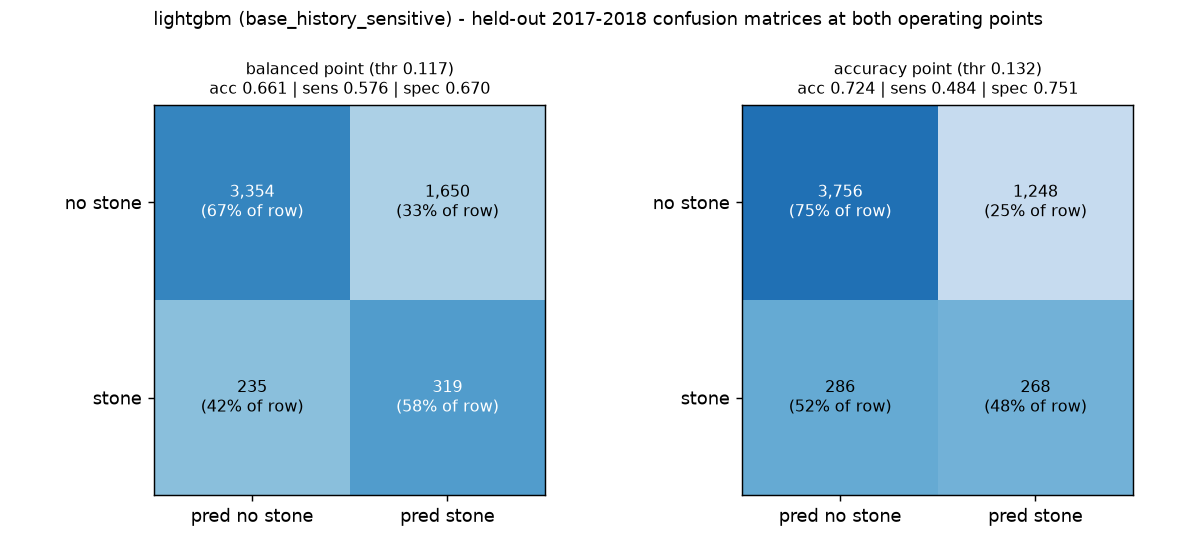

accuracy goal (> 70%) on the held-out test cycle: REACHED - accuracy 0.724, sensitivity 0.484, specificity 0.751 (majority baseline 0.900)


10.02

In [14]:
test_out = {}
for v in data:
    out = nc.final_test_evaluation(bundles[v], MODEL_NAME, v, fingerprints[v])
    results["variants"][v]["test"] = out["result"]
    test_out[v] = out
print("evaluated on:", results["variants"][PRIMARY]["test"]["evaluated_on"], "| n =", results["variants"][PRIMARY]["test"]["n"],
      "| prevalence =", round(results["variants"][PRIMARY]["test"]["prevalence"], 4),
      "| majority-class (predict 'no stone' for all) accuracy =", round(results["variants"][PRIMARY]["test"]["majority_baseline_accuracy"], 4))
final_table = nc.show_metrics_table(None, "FINAL TEST EVALUATION - both operating points - bootstrap 95% CI (1,000 resamples) - held-out 2017-2018",
                                    name=f"{MODEL_KEY}_06_final_test", results={v: results["variants"][v]["test"] for v in data})
p = nc.plot_calibration({v: (test_out[v]["y"], test_out[v]["p"]) for v in data}, nc.charts_dir() / f"{MODEL_KEY}_calibration_test.png",
                        f"{MODEL_KEY}: held-out test calibration")
thr_primary = {pt: bundles[PRIMARY].thresholds[pt] for pt in nc.OPERATING_POINTS}
cm_path = nc.plot_confusion_matrices(test_out[PRIMARY]["y"], test_out[PRIMARY]["p"], thr_primary,
                                     nc.charts_dir() / f"{MODEL_KEY}_confusion_test.png",
                                     f"{MODEL_KEY} ({PRIMARY}) - held-out 2017-2018 confusion matrices at both operating points")
display(Image(filename=str(cm_path)))
acc_pt = results["variants"][PRIMARY]["test"]["at_threshold"][nc.OP_ACCURACY]
if acc_pt is not None:
    verdict = "REACHED" if acc_pt["accuracy"] > nc.ACC_GOAL_TEST else "NOT reached"
    print(f"accuracy goal (> {nc.ACC_GOAL_TEST:.0%}) on the held-out test cycle: {verdict} - accuracy {acc_pt['accuracy']:.3f}, "
          f"sensitivity {acc_pt['sensitivity']:.3f}, specificity {acc_pt['specificity']:.3f} (majority baseline "
          f"{results['variants'][PRIMARY]['test']['majority_baseline_accuracy']:.3f})")
timer.lap("final_test")

## 11. Imbalance strategies on the test cycle (display only)

The strategy was frozen in section 4 and the registered model in section 9; this cell only *shows* how each strategy (default hyper-parameters, validation-derived calibrators and thresholds) behaves on test. Nothing here feeds back into any choice.

In [15]:
strat_test = {}
for s in nc.IMBALANCE_STRATEGIES:
    strat_test[s] = nc.final_test_evaluation(strat_bundles[s], f"{MODEL_NAME}__imb_{s}", PRIMARY, strat_fp[s])["result"]
strat_test_table = nc.show_metrics_table(None, "IMBALANCE STRATEGIES - held-out TEST (display only; the strategy was frozen on validation before this cell) - bootstrap 95% CI",
                                         name=f"{MODEL_KEY}_05_imbalance_test", results=strat_test)
auc_tab = pd.DataFrame({s: {"test ROC-AUC": strat_test[s]["roc_auc"], "test PR-AUC": strat_test[s]["pr_auc"], "test Brier": strat_test[s]["brier"]}
                        for s in nc.IMBALANCE_STRATEGIES}).T
print("test ranking / calibration by strategy (default hyper-parameters):")
print(auc_tab.round(4).to_string())
print(f"validation-selected strategy: {SELECTED}. ROC-AUC spread across strategies on test: "
      f"{auc_tab['test ROC-AUC'].min():.4f} - {auc_tab['test ROC-AUC'].max():.4f}; 'none' = {auc_tab.loc['none', 'test ROC-AUC']:.4f}.")
timer.lap("strategy_test")

=== METRICS TABLE: IMBALANCE STRATEGIES - held-out TEST (display only; the strategy was frozen on validation before this cell) - bootstrap 95% CI ===
model/strategy    point Threshold              ROC-AUC               PR-AUC                   Brier             Accuracy         Balanced acc          Sensitivity          Specificity            Precision                   F1                  MCC Majority acc        Pos-pred rate   TN   FP  FN  TP
          none balanced    0.1135 0.676 [0.654, 0.700] 0.190 [0.168, 0.220] 0.0862 [0.0805, 0.0921] 0.637 [0.625, 0.649] 0.627 [0.607, 0.650] 0.616 [0.577, 0.658] 0.639 [0.626, 0.653] 0.159 [0.143, 0.174] 0.252 [0.230, 0.274] 0.157 [0.130, 0.184]        0.900 0.386 [0.374, 0.399] 3198 1806 213 341
          none accuracy    0.1316 0.676 [0.654, 0.700] 0.190 [0.168, 0.220] 0.0862 [0.0805, 0.0921] 0.723 [0.711, 0.733] 0.624 [0.603, 0.645] 0.502 [0.460, 0.543] 0.747 [0.736, 0.760] 0.180 [0.160, 0.200] 0.265 [0.240, 0.290] 0.166 [0.136, 0.196]      

15.82

## 12. Explanations

Global importance is computed on a sample of the **validation** cycle (never the test cycle) as the mean absolute per-feature contribution on the log-odds scale; one-hot columns are summed back to the raw feature. Contributions describe what the model uses, not causes.

In [16]:
imp = nc.global_importance(bundles[PRIMARY], splits["validation"])
display(imp.head(10).round(4))
nc.plot_importance(imp["feature"].tolist(), imp["mean_abs_contribution"].tolist(), nc.charts_dir() / f"{MODEL_KEY}_importance.png",
                   f"{MODEL_KEY}: top features ({PRIMARY})")
for v in data:
    results["variants"][v]["importance_validation"] = nc.global_importance(bundles[v], splits["validation"]).head(10).to_dict(orient="records")
ex = splits["validation"].loc[splits["validation"].target_stone == 1].head(1)
c = pd.Series(bundles[PRIMARY].contributions(ex)[0], index=bundles[PRIMARY].input_features)
print("Local explanation for one validation positive (top 5 by |contribution|):")
print(c.reindex(c.abs().sort_values(ascending=False).index).head(5).round(3).to_string())

,feature,mean_abs_contribution
0,RIDAGEYR,0.2608
1,RIDRETH1,0.2557
2,URXUMA,0.1295
3,BPQ020,0.1225
4,BMXWAIST,0.0983
5,LBXSPH,0.0691
6,DIQ010,0.0666
7,MCQ080,0.0664
8,BPQ080,0.0662
9,LBXSCLSI,0.0614


Local explanation for one validation positive (top 5 by |contribution|):
RIDRETH1    0.361
RIDAGEYR    0.215
URXUMA      0.212
BMXWAIST    0.158
URXUCR      0.133


## 13. Save artifacts

Metrics JSON (`ml/outputs/metrics/nhanes_v003/<model>.json`) with provenance (notebook file, execution timestamp, device, training time, library versions, split hash), calibration and importance plots, tuning tables, metric-table CSVs and the frozen bundles.

In [17]:
timer.lap("explanations")
fit_seconds = round(sum(timer.sections.get(k, 0) for k in ("baseline", "imbalance_comparison", "tuning_and_final_fit", "loco_cv", "calibration")), 2)
for v in data:   # per-variant bookkeeping used by notebook 05
    results["variants"][v]["imbalance"] = ({"selected": SELECTED, "table": strat_table.reset_index().to_dict(orient="records"), "selection": select_info,
                                            "test": {s: strat_test[s] for s in nc.IMBALANCE_STRATEGIES},
                                            "validation_operating_points": {s: strat_fit[s]["operating_points"] for s in nc.IMBALANCE_STRATEGIES}}
                                           if v == PRIMARY else {"selected": SELECTED, "note": "strategy selected on the registered variant"})
results.update({
    "primary_variant": PRIMARY, "split_hash": manifest["hash"], "split_counts": manifest["counts"],
    "split_positive_rate": manifest["positive_rate"], "seed": nc.SEED, "dry_run": nc.is_dry_run(),
    "validation_halves": {"hash": halves["hash"], "early_stopping_n": int(len(ES)), "calibration_n": int(len(CAL)),
                          "early_stopping_positives": int(VAL[PRIMARY]["yes"].sum()), "calibration_positives": int(VAL[PRIMARY]["ycal"].sum())},
    "imbalance_strategy": SELECTED, "operating_point_rule": {nc.OP_BALANCED: nc.OP_RULE[nc.OP_BALANCED], nc.OP_ACCURACY: nc.OP_RULE[nc.OP_ACCURACY]},
    "device": {"requested": DEVICE, "actual": TRAIN_DEVICE, "hardware": devices["nvidia_smi"], "probe": devices},
    "training_seconds": fit_seconds, "notebook_seconds": timer.total, "section_seconds": timer.sections,
    "trained_at": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
})
results["provenance"] = nc.provenance(NOTEBOOK_FILE, timer, results["device"], manifest["hash"], fit_seconds)
out = nc.save_json(results, nc.metrics_dir() / f"{MODEL_KEY}.json")
print("saved", nc.rel(out))
print(f"device used for training: {results['device']['actual']} | training time (fits + tuning + CV): {fit_seconds}s | notebook total: {timer.total}s")
print(f"PROVENANCE notebook={NOTEBOOK_FILE} executed_at={results['provenance']['executed_at']} split_hash={manifest['hash']}")

saved ml/outputs/metrics/nhanes_v003/lightgbm.json
device used for training: cpu | training time (fits + tuning + CV): 115.39s | notebook total: 161.97s
PROVENANCE notebook=04_lightgbm.ipynb executed_at=2026-10-15T08:46:54Z split_hash=a2c3bdb15ffb9f3b943ec517e878cd8c59a92c444acd15ef7e35446fd0fcc7e7
